# 05 · Falcon 9 Recovery — Exploratory Visualisation
**Historical IBM dataset | Reproducible EDA and model-ready feature preview**

Explores flight sequence, payload mass, launch site, orbit and time trends using the **labelled output of Notebook 02**. Unlike the original course plots, the figures are consistently sized and annotated, with outcome definitions made explicit.

`Class = 1` denotes successful recovery under the IBM historical coding convention; `Class = 0` denotes failed or absent successful recovery. The observations are **descriptive associations, not causal effects**. Original notebook preserved in `original-coursework/`.

## 1. Load and validate the labelled dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
ROOT=Path.cwd(); PROCESSED=ROOT/'data'/'processed'; FIGURES=ROOT/'images'
FIGURES.mkdir(parents=True,exist_ok=True)
source=PROCESSED/'falcon9_labeled_historical.csv'
if not source.exists():
    raise FileNotFoundError(f'{source} not found. Run Notebook 02 first.')
df=pd.read_csv(source)
required={'Date','Class','FlightNumber','PayloadMass','Orbit','LaunchSite','Flights','GridFins','Reused','Legs','Block','ReusedCount','LandingPad','Serial'}
if missing:=required-set(df.columns): raise ValueError(f'Missing columns: {sorted(missing)}')
df['Date']=pd.to_datetime(df['Date'],errors='raise')
df['Class']=pd.to_numeric(df['Class'],errors='raise').astype(int)
assert df['Class'].isin([0,1]).all()
print('Shape:',df.shape)
display(df.head())
sns.set_theme(style='whitegrid',context='notebook')
def finish(name):
    plt.tight_layout()
    plt.savefig(FIGURES/name,dpi=160,bbox_inches='tight')
    plt.show()

Shape: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## 2. Flight number, payload and recovery

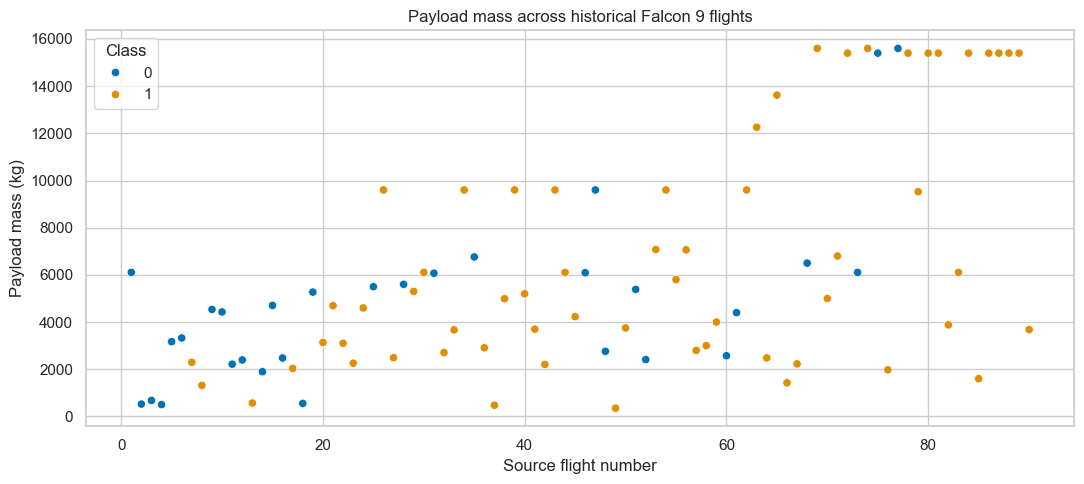

In [2]:
fig,ax=plt.subplots(figsize=(11,5))
sns.scatterplot(data=df,x='FlightNumber',y='PayloadMass',hue='Class',palette='colorblind',ax=ax)
ax.set(title='Payload mass across historical Falcon 9 flights',xlabel='Source flight number',ylabel='Payload mass (kg)')
finish('spacex_flight_payload.png')

## 3. Launch site and payload distributions

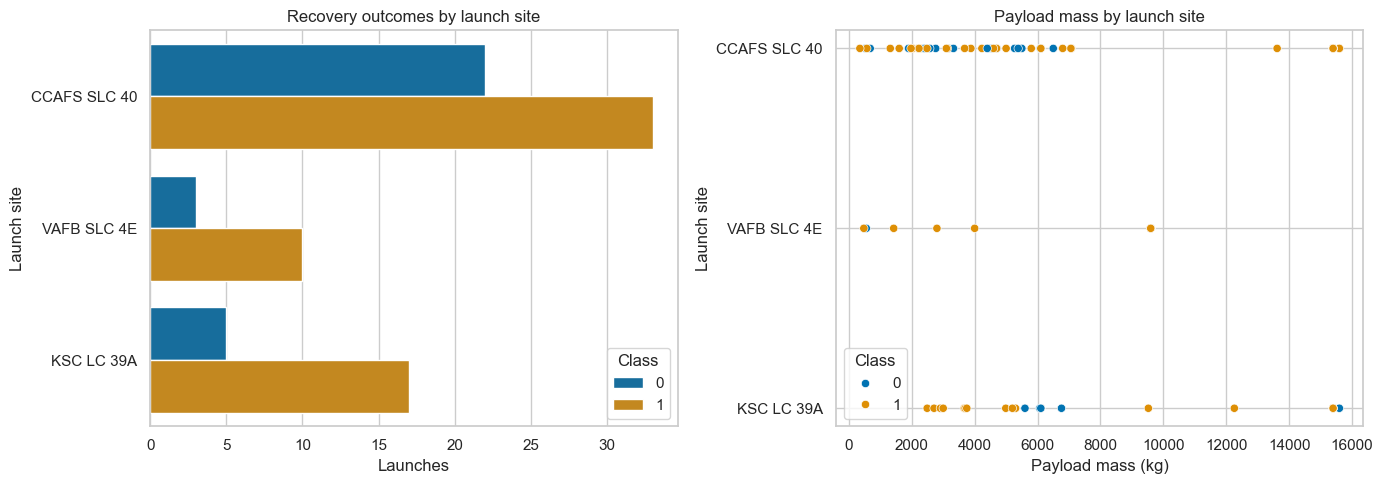

In [3]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.countplot(data=df,y='LaunchSite',hue='Class',palette='colorblind',ax=axes[0])
axes[0].set(title='Recovery outcomes by launch site',xlabel='Launches',ylabel='Launch site')
sns.scatterplot(data=df,x='PayloadMass',y='LaunchSite',hue='Class',palette='colorblind',ax=axes[1])
axes[1].set(title='Payload mass by launch site',xlabel='Payload mass (kg)',ylabel='Launch site')
finish('spacex_launch_sites.png')

## 4. Orbit-level success rates

A success proportion without a denominator can be misleading, particularly for rare orbits. We show **both the rate and the number of launches**.

,recovery_rate,launches
Orbit,,
SO,0.000000,1
GTO,0.518519,27
ISS,0.619048,21
MEO,0.666667,3
PO,0.666667,9
LEO,0.714286,7
VLEO,0.857143,14
HEO,1.000000,1
GEO,1.000000,1


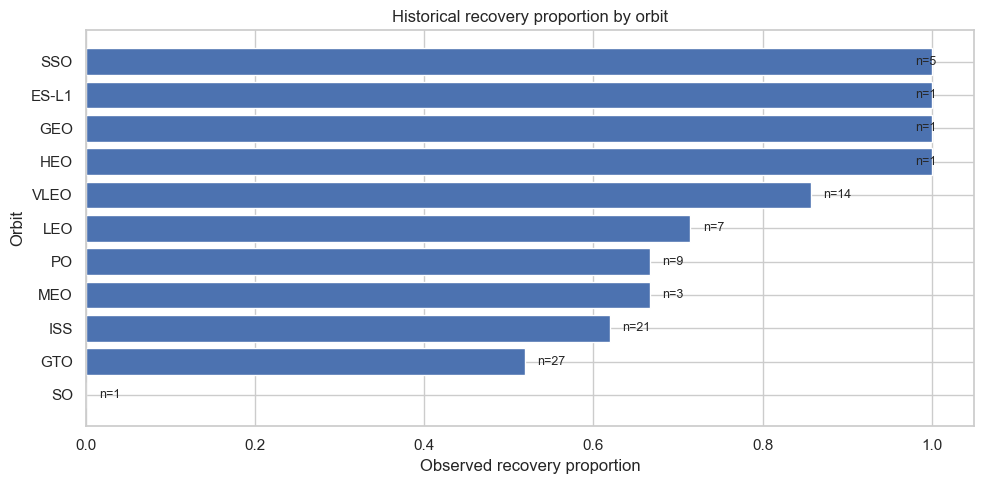

In [4]:
orbit_summary=(df.groupby('Orbit',dropna=False)['Class'].agg(['mean','count']).rename(columns={'mean':'recovery_rate','count':'launches'}).sort_values('recovery_rate'))
display(orbit_summary)
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(orbit_summary.index.astype(str),orbit_summary['recovery_rate'])
for i,(_,row) in enumerate(orbit_summary.iterrows()):
    ax.text(min(row['recovery_rate']+0.015,0.98),i,f"n={int(row['launches'])}",va='center',fontsize=9)
ax.set(xlim=(0,1.05),xlabel='Observed recovery proportion',ylabel='Orbit',title='Historical recovery proportion by orbit')
finish('spacex_orbit_recovery_rates.png')

## 5. Yearly recovery trend and sample sizes

,recovery_rate,launches
Year,,
2010,0.000000,1
2012,0.000000,1
2013,0.000000,3
2014,0.333333,6
2015,0.333333,6
2016,0.625000,8
2017,0.833333,18
2018,0.611111,18
2019,0.900000,10


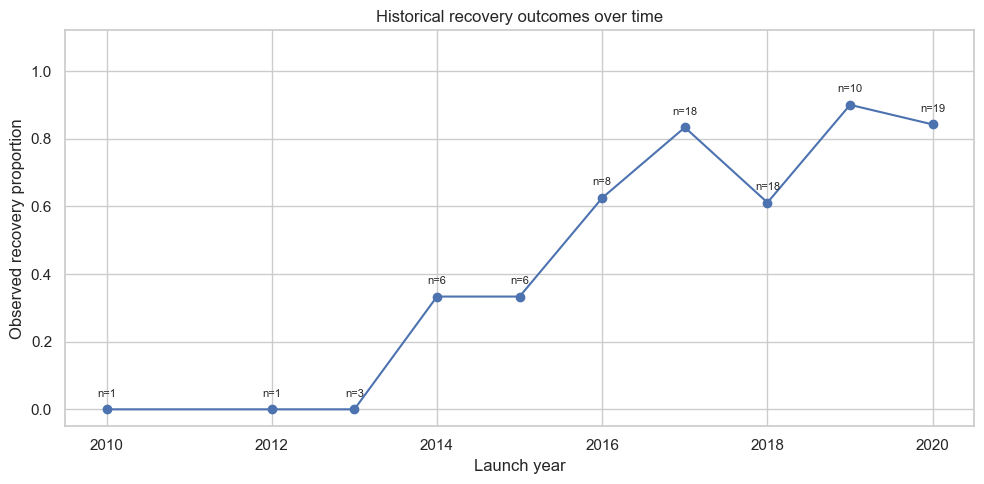

In [5]:
df['Year']=df['Date'].dt.year
yearly=df.groupby('Year')['Class'].agg(['mean','count']).rename(columns={'mean':'recovery_rate','count':'launches'})
display(yearly)
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(yearly.index,yearly['recovery_rate'],marker='o')
for year,row in yearly.iterrows():
    ax.annotate(f"n={int(row['launches'])}",(year,row['recovery_rate']),xytext=(0,9),textcoords='offset points',ha='center',fontsize=8)
ax.set(ylim=(-0.05,1.12),xlabel='Launch year',ylabel='Observed recovery proportion',title='Historical recovery outcomes over time')
finish('spacex_recovery_by_year.png')

## 6. Feature preparation — preview only

Categorical encoding is illustrated for later modelling, **not fitted as a production pipeline**. Missing numeric values are left missing. In the ML notebook, train/test splitting must precede fitting imputers, encoders or scalers.

In [6]:
feature_columns=['FlightNumber','PayloadMass','Orbit','LaunchSite','Flights','GridFins','Reused','Legs','LandingPad','Block','ReusedCount','Serial']
features=df[feature_columns].copy()
encoded_preview=pd.get_dummies(features,columns=['Orbit','LaunchSite','LandingPad','Serial'],dummy_na=True,dtype=int)
print('Feature preview shape:',encoded_preview.shape)
print('Missing values (numeric features retained):')
display(encoded_preview.isna().sum().loc[lambda s:s>0].to_frame('missing'))
display(encoded_preview.head())

Feature preview shape: (90, 84)
Missing values (numeric features retained):


,missing


,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062,Serial_nan
0,1,6104.959412,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,525.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,677.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,500.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,3170.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Findings and limitations
- Orbit and site recovery rates are descriptive and can be affected by small samples and changing launch technology.
- Flight number and year are correlated with technological progression, so they require careful interpretation.
- Missing payload mass has **not** been globally imputed.
- **Do not train models on the one-hot preview above** without a train-only preprocessing pipeline.
- The next stage can add geospatial mapping and machine learning, while retaining this historical scope.